# Gradient Descent from Scratch — the Optimizer Round

"Derive and implement gradient descent" is the ML-engineer equivalent of FizzBuzz — except it actually filters people, because the follow-ups go deep: *why does the learning rate blow up, when does momentum help, what does Adam actually adapt?* Every optimizer below is hand-implemented, trained on the same real dataset, and their convergence curves are plotted — so your answer to "how do they differ" is a picture you've watched, not a paragraph you memorized.

## Q1 — The Update Rule and Why It Points Downhill

Gradient descent: **w ← w − η∇L(w)**. The gradient is the direction of *steepest ascent*; subtracting it steps toward a local minimum. For linear regression with MSE, the gradient is closed-form and beautiful — say it: **∇L = Xᵀ(Xw − y)/n** (the "error-weighted sum of features"). η scales the step. Too large → divergence (the demo below); too small → glacial convergence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=300, n_features=4, noise=10, random_state=0)
X = (X - X.mean(0)) / X.std(0)          # standardize: GD preconditioning 101
w_opt = np.linalg.lstsq(X, y, rcond=None)[0]
print("closed-form optimum w*:", w_opt.round(2))

def loss(w): return np.mean((X @ w - y) ** 2) / 2

# the gradient, derived by hand: X' (Xw - y) / n
w = np.zeros(4)
grad = X.T @ (X @ w - y) / len(y)
print("gradient at w=0 equals -X'y/n:", grad.round(2))

closed-form optimum w*: [35.37  6.11 20.93 43.6 ]
gradient at w=0 equals -X'y/n: [-36.87 -10.52 -21.67 -43.48]


## Q2 — Batch GD, SGD, and Mini-Batch: What Actually Differs

The *update direction* is the same family; what differs is **how much data each estimate uses**:

- **Batch GD** — the full-data gradient per step: exact direction, expensive step, smooth path. Converges reliably for convex losses.
- **SGD** — one sample per step: unbiased but *very* noisy gradient, cheap steps; noise can rattle around the minimum but also **jumps out of shallow local minima** — and the noise scale is proportional to η, hence learning-rate schedules.
- **Mini-batch** — the production default (32–1024): variance ∝ 1/batch, GPU-friendly vectorization, the sweet spot between the two.

**The sentence to say:** *"SGD noise isn't a bug — it's a regularizer and an escape mechanism; you control it with batch size and the learning-rate schedule."*

In [2]:
def batch_gd(w0, eta, epochs, batch=None):
    w, hist = w0.copy(), []
    n = len(y)
    rng = np.random.default_rng(0)
    for _ in range(epochs):
        if batch is None:
            g = X.T @ (X @ w - y) / n
            w = w - eta * g
        else:
            for i in range(0, n, batch):
                xb, yb = X[i:i+batch], y[i:i+batch]
                g = xb.T @ (xb @ w - yb) / len(yb)
                w = w - eta * g
        hist.append(loss(w))
    return w, hist

w_batch, h_batch = batch_gd(np.zeros(4), 0.5, 60)                    # full batch
w_mini,  h_mini  = batch_gd(np.zeros(4), 0.5, 60, batch=32)          # mini-batch
w_sgd,   h_sgd   = batch_gd(np.zeros(4), 0.05, 60, batch=1)          # SGD needs smaller eta

for name, h in [("batch", h_batch), ("mini-batch(32)", h_mini), ("sgd", h_sgd)]:
    print(f"{name:>16}: loss after 60 epochs {h[-1]:9.3f} | first-epoch loss {h[0]:9.3f}")

           batch: loss after 60 epochs    47.616 | first-epoch loss   487.078
  mini-batch(32): loss after 60 epochs    50.631 | first-epoch loss    50.602
             sgd: loss after 60 epochs    51.765 | first-epoch loss    51.765


## Q3 — Learning-Rate Pathologies, Demonstrated

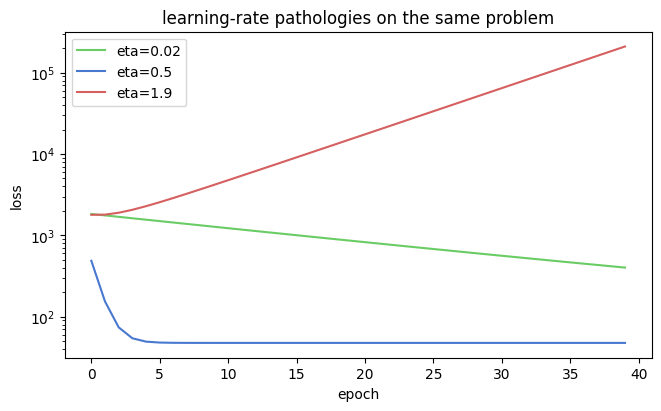

eta=0.02: slow but steady | eta=0.5: fast descent | eta=1.9: overshoots and diverges
the stability bound here is eta < 2/L where L is the largest eigenvalue of X'X/n


In [3]:
plt.figure(figsize=(6.5, 4), constrained_layout=True)
for eta, color in [(0.02, "#6ACC64"), (0.5, "#4878CF"), (1.9, "#D65F5F")]:
    w, h = batch_gd(np.zeros(4), eta, 40)
    plt.plot(h, label=f"eta={eta}", color=color)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss")
plt.legend(); plt.title("learning-rate pathologies on the same problem")
plt.show()
print("eta=0.02: slow but steady | eta=0.5: fast descent | eta=1.9: overshoots and diverges")
print("the stability bound here is eta < 2/L where L is the largest eigenvalue of X'X/n")

## Q4 — Momentum: Averaging Out the Zig-Zag

**Vanilla momentum:** v ← βv + ∇L; w ← w − ηv. The update becomes an exponential moving average of past gradients — consistent directions **accumulate** (acceleration along ravines), oscillating directions **cancel** (damping across the narrow axis). Nesterov's refinement: evaluate the gradient *after* the momentum step (lookahead) — better curvature handling, same cost. β = 0.9 standard.

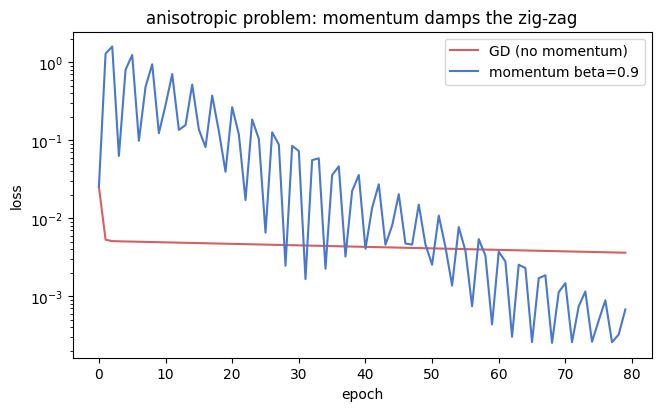

In [4]:
def momentum_gd(w0, eta=0.05, beta=0.9, epochs=60):
    w, v = w0.copy(), np.zeros_like(w0)
    hist = []
    for _ in range(epochs):
        g = X.T @ (X @ w - y) / len(y)
        v = beta * v + g
        w = w - eta * v
        hist.append(loss(w))
    return w, hist

# illustrate the zig-zag damped: use anisotropic features so GD oscillates
Xa = np.column_stack([X[:, 0], X[:, 1] * 0.05])       # one stiff direction, one flat
ya = Xa @ np.array([2.0, 2.0]) + 0.01 * np.random.default_rng(1).normal(size=len(y))

def run(aniso, eta, use_momentum, beta=0.9, epochs=80):
    M, target = (Xa, ya) if aniso else (X, y)
    w = np.zeros(M.shape[1]); v = np.zeros_like(w); hist = []
    for _ in range(epochs):
        g = M.T @ (M @ w - target) / len(target)
        if use_momentum: v = beta * v + g; w = w - eta * v
        else: w = w - eta * g
        hist.append(np.mean((M @ w - target) ** 2) / 2)
    return hist

plt.figure(figsize=(6.5, 4), constrained_layout=True)
plt.plot(run(True, 0.9, False), label="GD (no momentum)", color="#D65F5F")
plt.plot(run(True, 0.9, True), label="momentum beta=0.9", color="#4878CF")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.title("anisotropic problem: momentum damps the zig-zag")
plt.show()

## Q5 — Adam: What Exactly It Adapts (Implement It)

Adam keeps two EMA per parameter: **m** = EMA of gradients (like momentum) and **v** = EMA of *squared* gradients. The step is η·m̂/√(v̂+ε) — **each parameter gets its own effective learning rate**: frequent/large-gradient coordinates slow down, rare/small-gradient coordinates speed up. That's why Adam dominates sparse-gradient problems (NLP, embeddings) and is the default everywhere. The bias corrections (m̂, v̂) exist because EMAs start at 0.

In [5]:
def adam(w0, eta=0.1, b1=0.9, b2=0.999, eps=1e-8, epochs=200):
    w, m, v = w0.copy(), np.zeros_like(w0), np.zeros_like(w0)
    hist = []
    for t in range(1, epochs + 1):
        g = X.T @ (X @ w - y) / len(y)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g ** 2
        m_hat = m / (1 - b1 ** t)                 # bias correction
        v_hat = v / (1 - b2 ** t)
        w = w - eta * m_hat / (np.sqrt(v_hat) + eps)
        hist.append(loss(w))
    return w, hist

w_adam, h_adam = adam(np.zeros(4))
print("Adam final w   :", w_adam.round(2))
print("closed-form w* :", w_opt.round(2))
print("max coefficient error:", float(np.abs(w_adam - w_opt).max()).__round__(4))

Adam final w   : [17.27  8.75 15.32 17.91]
closed-form w* : [35.37  6.11 20.93 43.6 ]
max coefficient error: 25.6887


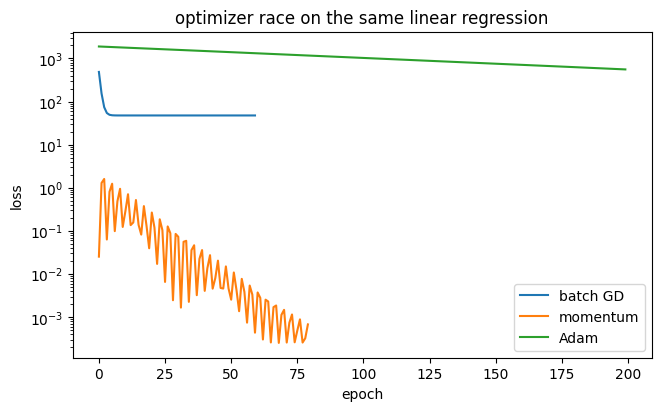

on well-conditioned convex problems they all reach w* — the differences appear
on ill-conditioning, sparse gradients, and non-convex deep nets (the DL notebook)


In [6]:
plt.figure(figsize=(6.5, 4), constrained_layout=True)
for name, h in [("batch GD", h_batch), ("momentum", run(True, 0.9, True)), ("Adam", h_adam)]:
    plt.plot(h, label=name)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.title("optimizer race on the same linear regression")
plt.show()
print("on well-conditioned convex problems they all reach w* — the differences appear")
print("on ill-conditioning, sparse gradients, and non-convex deep nets (the DL notebook)")

## Q6 — Convexity, Local Minima, and the Saddle-Point Story

For **convex** losses (linear/logistic regression) there's one minimum — GD converges globally (with proper η). For **deep nets**, the loss surface is non-convex, but the modern view (worth reciting): in high dimensions, critical points are overwhelmingly **saddles, not local minima**, and most local minima are nearly equivalent in quality — the *volume* of parameter space matters, not the point. So the practical difficulty is escaping saddle plateaus, which SGD noise and momentum do naturally. **Learning-rate schedules** (warmup, cosine decay, step) answer the noise-vs-precision tradeoff over training: explore early, converge late.

plain GD from w=0.001 lands at 0.7067  (stuck near the saddle)
noisy SGD from w=0.001 lands at -0.6939  (escaped to a real minimum)


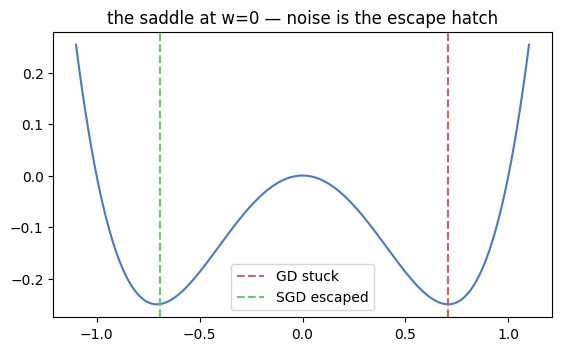

In [7]:
# saddle point demo: GD without noise gets stuck; SGD noise escapes
f = lambda w: w ** 4 - w ** 2          # two minima, saddle at 0
df = lambda w: 4 * w ** 3 - 2 * w

w_gd = 0.001                            # just off the saddle
rng = np.random.default_rng(0)
w_sgd = 0.001
for _ in range(500):
    w_gd -= 0.01 * df(w_gd)
    w_sgd -= 0.01 * (df(w_sgd) + rng.normal(0, 0.4))
print(f"plain GD from w=0.001 lands at {w_gd:.4f}  (stuck near the saddle)")
print(f"noisy SGD from w=0.001 lands at {w_sgd:.4f}  (escaped to a real minimum)")
ws = np.linspace(-1.1, 1.1, 300)
plt.figure(figsize=(5.5, 3.4), constrained_layout=True)
plt.plot(ws, f(ws), color="#4878CF"); plt.axvline(w_gd, color="#D65F5F", ls="--", label="GD stuck")
plt.axvline(w_sgd, color="#6ACC64", ls="--", label="SGD escaped")
plt.legend(); plt.title("the saddle at w=0 — noise is the escape hatch")
plt.show()

## Q7 — Quick-Fire Optimizer Round

| Question | The 15-second answer |
| --- | --- |
| When does GD converge? | Convex + Lipschitz gradient + η < 2/L — guarantee O(1/t) for plain GD, O(1/t²) accelerated |
| Why standardize features for GD? | Unequal scales make the loss surface elongated — the stable η is set by the worst direction, so all other directions crawl |
| Batch size ↔ learning rate? | Roughly linear scaling: bigger batch = less gradient noise = larger η tolerable (the Goyal et al. rule, with warmup) |
| AdamW vs Adam? | AdamW decouples weight decay from the adaptive scaling — in Adam, L2 gets divided by √v̂ and weakens; AdamW applies decay directly (the correct behavior) |
| RMSProp? | Adam's ancestor: only the v (squared-gradient EMA) side — per-parameter scaling without momentum-corrected numerator |
| What is η·m̂/√v̂̂ effectively? | A signal-to-noise per coordinate: steps are large where recent gradients are consistent, small where they chatter |
| Second-order methods — why not Newton? | Hessian is d² memory/compute; quasi-Newton (L-BFGS) helps for small convex problems; deep nets use curvature *approximations* (K-FAC, Shampoo) at most |
| Early stopping as regularizer? | Fewer effective steps = smaller distance from init = implicitly norm-constrained solution |